# NA-DyCNN Retinal OCT Pipeline

A self-contained demonstration of adaptive enhancement, dynamic convolution, dual-branch noise-aware training, and Mondrian conformal prediction. It uses synthetic B-scans so the full pipeline runs without downloading a dataset.

In [1]:
import random
from typing import Dict, List, Tuple

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import DataLoader, Dataset, random_split

SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


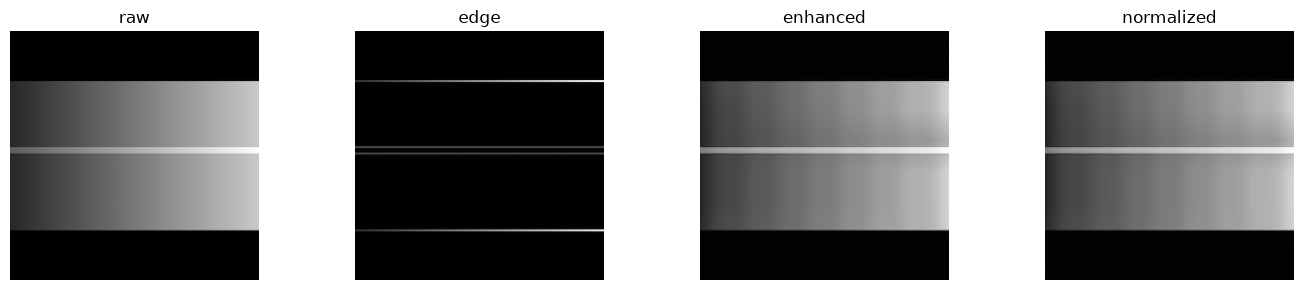

In [2]:
def square_pad_resize(image: np.ndarray, size: int = 256) -> np.ndarray:
    image = np.asarray(image, dtype=np.float32)
    height, width = image.shape[:2]
    side = max(height, width)
    padded = np.zeros((side, side), dtype=np.float32)
    y0, x0 = (side - height) // 2, (side - width) // 2
    padded[y0:y0 + height, x0:x0 + width] = image
    return cv2.resize(padded, (size, size), interpolation=cv2.INTER_LANCZOS4)

def adaptive_enhance(image: np.ndarray, size: int = 256) -> Dict[str, np.ndarray]:
    resized = np.clip(square_pad_resize(image, size), 0, 1)
    gx = cv2.Sobel(resized, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(resized, cv2.CV_32F, 0, 1, ksize=3)
    edge = cv2.normalize(np.sqrt(gx * gx + gy * gy), None, 0, 1, cv2.NORM_MINMAX)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    clahe_image = clahe.apply((resized * 255).astype(np.uint8)).astype(np.float32) / 255.0
    enhanced = edge * resized + (1.0 - edge) * clahe_image
    normalized = (enhanced - enhanced.mean()) / (enhanced.std() + 1e-7)
    return {"raw": resized, "edge": edge, "enhanced": enhanced, "normalized": normalized}

demo_scan = np.tile(np.linspace(0.15, 0.75, 320, dtype=np.float32), (192, 1))
demo_scan[85:93] += 0.2
demo = adaptive_enhance(demo_scan)
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for axis, (name, image) in zip(axes, demo.items()):
    axis.imshow(image, cmap="gray")
    axis.set_title(name.replace("_", " "))
    axis.axis("off")
plt.tight_layout()
plt.show()

In [3]:
class DynamicConv2d(nn.Module):
    """Per-sample mixture of K depthwise experts with a compact router."""
    def __init__(self, in_channels: int, out_channels: int, kernel_size: int = 3, stride: int = 1,
                 experts: int = 4, reduction: int = 8):
        super().__init__()
        self.in_channels, self.out_channels = in_channels, out_channels
        self.kernel_size, self.stride, self.experts = kernel_size, stride, experts
        reduced = max(4, min(in_channels, reduction))
        self.router = nn.Sequential(
            nn.Conv2d(in_channels, reduced, 1), nn.ReLU(inplace=True),
            nn.Conv2d(reduced, experts, 1)
        )
        self.depthwise = nn.Parameter(torch.randn(experts, in_channels, kernel_size, kernel_size) * 0.05)
        self.project = nn.Conv2d(in_channels, out_channels, 1, bias=False)
        self.last_alpha = None

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        batch_size = x.shape[0]
        alpha = F.softmax(self.router(F.adaptive_avg_pool2d(x, 1)).flatten(1), dim=-1)
        self.last_alpha = alpha.detach()
        mixed = torch.einsum("bk,kcij->bcij", alpha, self.depthwise)
        grouped_input = x.reshape(1, batch_size * self.in_channels, x.shape[-2], x.shape[-1])
        output = F.conv2d(grouped_input, mixed.reshape(batch_size * self.in_channels, 1, self.kernel_size, self.kernel_size),
                          stride=self.stride, padding=self.kernel_size // 2, groups=batch_size * self.in_channels)
        output = output.reshape(batch_size, self.in_channels, output.shape[-2], output.shape[-1])
        return self.project(output)

class DynamicResidualBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, stride: int):
        super().__init__()
        self.dynamic1 = DynamicConv2d(in_channels, out_channels, stride=stride)
        self.norm1 = nn.BatchNorm2d(out_channels)
        self.dynamic2 = DynamicConv2d(out_channels, out_channels)
        self.norm2 = nn.BatchNorm2d(out_channels)
        self.skip = nn.Sequential(nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False), nn.BatchNorm2d(out_channels)) if (in_channels != out_channels or stride != 1) else nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        residual = self.skip(x)
        x = F.relu(self.norm1(self.dynamic1(x)), inplace=True)
        return F.relu(self.norm2(self.dynamic2(x)) + residual, inplace=True)

class NADyCNN(nn.Module):
    def __init__(self, num_classes: int = 3):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(inplace=True))
        self.blocks = nn.ModuleList([
            DynamicResidualBlock(32, 32, 1), DynamicResidualBlock(32, 64, 2),
            DynamicResidualBlock(64, 128, 2), DynamicResidualBlock(128, 256, 2)])
        self.head = nn.Linear(256, num_classes)

    def forward(self, x: torch.Tensor, return_features: bool = False) -> torch.Tensor:
        x = self.stem(x)
        for block in self.blocks:
            x = block(x)
        features = F.adaptive_avg_pool2d(x, 1).flatten(1)
        logits = self.head(features)
        return (logits, features) if return_features else logits

model = NADyCNN().to(device)
parameter_count = sum(parameter.numel() for parameter in model.parameters())
print(f"Parameters: {parameter_count:,} (target <= 500,000: {parameter_count <= 500_000})")

Parameters: 210,755 (target <= 500,000: True)


In [4]:
class SyntheticOCT(Dataset):
    class_names = ("Normal", "AMD", "DME")

    def __init__(self, samples_per_class: int = 24, size: int = 64, seed: int = SEED):
        self.images, self.labels = [], []
        rng = np.random.default_rng(seed)
        y = np.linspace(0, 1, size)[:, None]
        x = np.linspace(0, 1, size)[None, :]
        for label in range(3):
            for _ in range(samples_per_class):
                image = 0.08 + 0.04 * rng.normal(size=(size, size))
                for layer, amplitude, thickness in ((0.27, .38, .035), (.45, .25, .025), (.67, .32, .03), (.82, .2, .02)):
                    curve = layer + 0.025 * np.sin(2 * np.pi * x + rng.uniform(0, 6.28))
                    image += amplitude * np.exp(-((y - curve) ** 2) / (2 * thickness ** 2))
                if label == 1:
                    for _ in range(3):
                        cx, cy = rng.uniform(.2, .8), rng.uniform(.38, .75)
                        image += .28 * np.exp(-(((x - cx) / .07) ** 2 + ((y - cy) / .035) ** 2))
                if label == 2:
                    for _ in range(2):
                        cx, cy = rng.uniform(.25, .75), rng.uniform(.38, .7)
                        image -= .18 * np.exp(-(((x - cx) / .08) ** 2 + ((y - cy) / .06) ** 2))
                image = cv2.GaussianBlur(np.clip(image, 0, 1).astype(np.float32), (3, 3), 0)
                image = adaptive_enhance(image, size)["normalized"]
                self.images.append(image.astype(np.float32))
                self.labels.append(label)

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, index: int) -> Tuple[torch.Tensor, torch.Tensor]:
        return torch.from_numpy(self.images[index][None]), torch.tensor(self.labels[index], dtype=torch.long)

dataset = SyntheticOCT()
train_set, calibration_set, test_set = random_split(dataset, [48, 12, 12], generator=torch.Generator().manual_seed(SEED))
train_loader = DataLoader(train_set, batch_size=12, shuffle=True)
calibration_loader = DataLoader(calibration_set, batch_size=12)
test_loader = DataLoader(test_set, batch_size=12)
print(f"Synthetic samples: {len(dataset)}")

Synthetic samples: 72


In [5]:
def noisy_batch(images: torch.Tensor, sigma: float = 0.10) -> torch.Tensor:
    clean = images.clamp(0, 1)
    normalized = (clean - clean.amin(dim=(-2, -1), keepdim=True)) / (clean.amax(dim=(-2, -1), keepdim=True) - clean.amin(dim=(-2, -1), keepdim=True) + 1e-6)
    return (normalized * (1 + sigma * torch.randn_like(normalized))).clamp(0, 1)

def dual_branch_loss(model: nn.Module, images: torch.Tensor, labels: torch.Tensor, beta: float = 0.10, samples: int = 4):
    clean_logits = model(images)
    clean_loss = F.cross_entropy(clean_logits, labels)
    noisy_logits = [model(noisy_batch(images)) for _ in range(samples)]
    noisy_loss = torch.stack([F.cross_entropy(logits, labels) for logits in noisy_logits]).mean()
    return clean_loss + beta * noisy_loss, clean_logits, noisy_logits

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=3)
history = {"loss": [], "clean_accuracy": [], "noise_accuracy": [], "routing_stability": []}
for epoch in range(3):
    model.train()
    totals = np.zeros(4, dtype=np.float64)
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        loss, clean_logits, noisy_logits = dual_branch_loss(model, images, labels)
        loss.backward()
        optimizer.step()
        clean_pred = clean_logits.argmax(1)
        noisy_pred = torch.stack([logits.argmax(1) for logits in noisy_logits]).mode(0).values
        alpha = torch.cat([block.dynamic1.last_alpha for block in model.blocks], dim=0)
        totals += [loss.item(), (clean_pred == labels).float().mean().item(), (noisy_pred == labels).float().mean().item(), alpha.std().item()]
    scheduler.step()
    totals /= len(train_loader)
    for key, value in zip(history, totals): history[key].append(value)
    print(f"Epoch {epoch + 1}: loss={totals[0]:.3f}, clean_acc={totals[1]:.2f}, noise_acc={totals[2]:.2f}, routing_std={totals[3]:.3f}")

Epoch 1: loss=1.166, clean_acc=0.42, noise_acc=0.29, routing_std=0.047
Epoch 2: loss=0.828, clean_acc=0.79, noise_acc=0.54, routing_std=0.051
Epoch 3: loss=0.607, clean_acc=0.90, noise_acc=0.56, routing_std=0.052


Mondrian quantiles: [0.972 0.063 0.965]
Prediction-set coverage: 75.0%; mean set size: 1.75


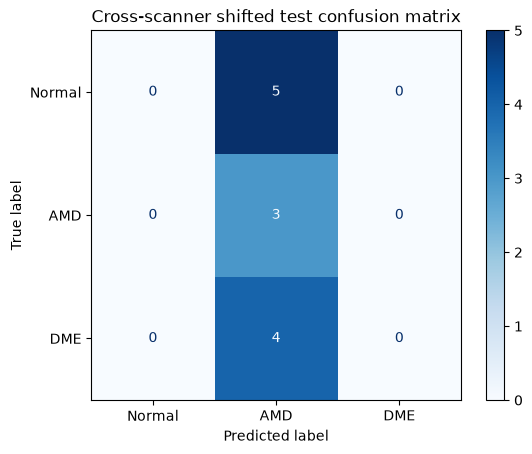

In [6]:
@torch.no_grad()
def probabilities(loader: DataLoader, noise_sigma: float = 0.0):
    model.eval(); all_probs, all_labels = [], []
    for images, labels in loader:
        images = images.to(device)
        if noise_sigma: images = noisy_batch(images, noise_sigma)
        all_probs.append(model(images).softmax(1).cpu())
        all_labels.append(labels)
    return torch.cat(all_probs), torch.cat(all_labels)

calibration_probs, calibration_labels = probabilities(calibration_loader, noise_sigma=0.10)
test_probs, test_labels = probabilities(test_loader, noise_sigma=0.15)
alpha = 0.10
quantiles = torch.full((3,), 1.0)
for class_id in range(3):
    scores = 1.0 - calibration_probs[calibration_labels == class_id, class_id]
    if len(scores):
        rank = min(len(scores), int(np.ceil((len(scores) + 1) * (1 - alpha))))
        quantiles[class_id] = scores.sort().values[rank - 1]
prediction_sets = test_probs >= (1.0 - quantiles)[None, :]
coverage = prediction_sets[torch.arange(len(test_labels)), test_labels].float().mean().item()
set_sizes = prediction_sets.sum(1).numpy()
predicted = test_probs.argmax(1).numpy()
print(f"Mondrian quantiles: {quantiles.numpy().round(3)}")
print(f"Prediction-set coverage: {coverage:.1%}; mean set size: {set_sizes.mean():.2f}")
ConfusionMatrixDisplay(confusion_matrix(test_labels.numpy(), predicted), display_labels=dataset.class_names).plot(cmap="Blues")
plt.title("Cross-scanner shifted test confusion matrix")
plt.show()

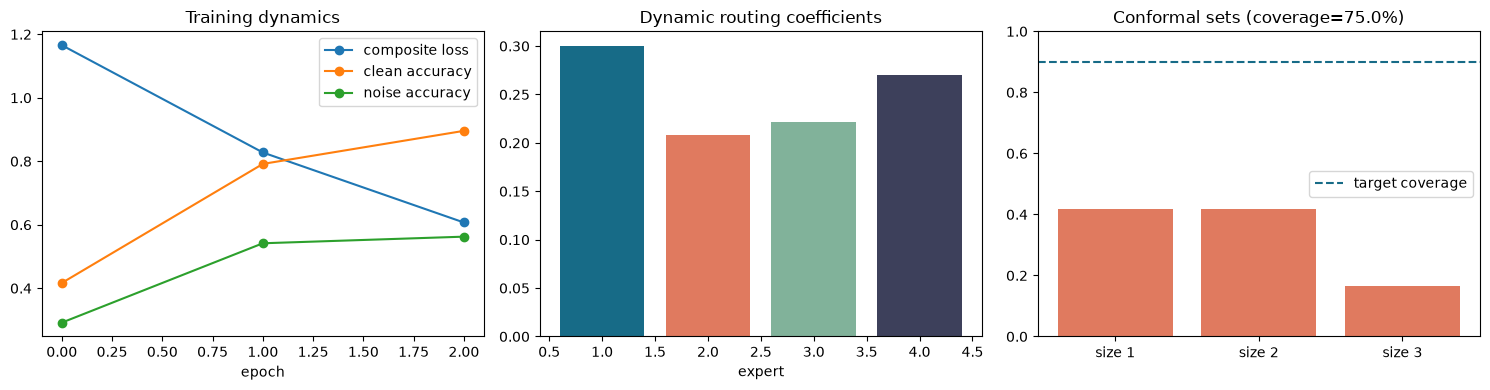

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(history["loss"], marker="o", label="composite loss")
axes[0].plot(history["clean_accuracy"], marker="o", label="clean accuracy")
axes[0].plot(history["noise_accuracy"], marker="o", label="noise accuracy")
axes[0].set_title("Training dynamics"); axes[0].set_xlabel("epoch"); axes[0].legend()
routing = torch.cat([block.dynamic1.last_alpha.cpu() for block in model.blocks], dim=0).mean(0).numpy()
axes[1].bar(np.arange(1, 5), routing, color=["#176b87", "#e07a5f", "#81b29a", "#3d405b"])
axes[1].set_title("Dynamic routing coefficients"); axes[1].set_xlabel("expert")
axes[2].bar(["size 1", "size 2", "size 3"], [(set_sizes == value).mean() for value in (1, 2, 3)], color="#e07a5f")
axes[2].axhline(1 - alpha, color="#176b87", linestyle="--", label="target coverage")
axes[2].set_ylim(0, 1); axes[2].set_title(f"Conformal sets (coverage={coverage:.1%})"); axes[2].legend()
plt.tight_layout(); plt.show()